In [182]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import skimage.feature as feature

import warnings
import mahotas
warnings.filterwarnings("ignore")

In [183]:
GROUP = "C7"
DTYPE="GLCM"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C7_10,28,"[DATA/TRAINING/C7/C7_10/IMG_8189.HEIC, DATA/TR..."
1,C7_11,27,"[DATA/TRAINING/C7/C7_11/IMG_8248.HEIC, DATA/TR..."
2,C7_12,25,"[DATA/TRAINING/C7/C7_12/IMG_8280.HEIC, DATA/TR..."
3,C7_13,25,"[DATA/TRAINING/C7/C7_13/IMG_8311.HEIC, DATA/TR..."
4,C7_14,25,"[DATA/TRAINING/C7/C7_14/IMG_8406.HEIC, DATA/TR..."
5,C7_15,25,"[DATA/TRAINING/C7/C7_15/IMG_8343.HEIC, DATA/TR..."
6,C7_16,27,"[DATA/TRAINING/C7/C7_16/IMG_8375.HEIC, DATA/TR..."


In [184]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [185]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [186]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

In [187]:
def read_image(pic_path):
    ext = pic_path.split(".")[1]
    if ext=="HEIC":
        return read_imgHEIC(pic_path)
    else:
        img=cv2.imread(pic_path)
        return img

Text(0.5, 1.0, '16% IMG_8434.HEIC')

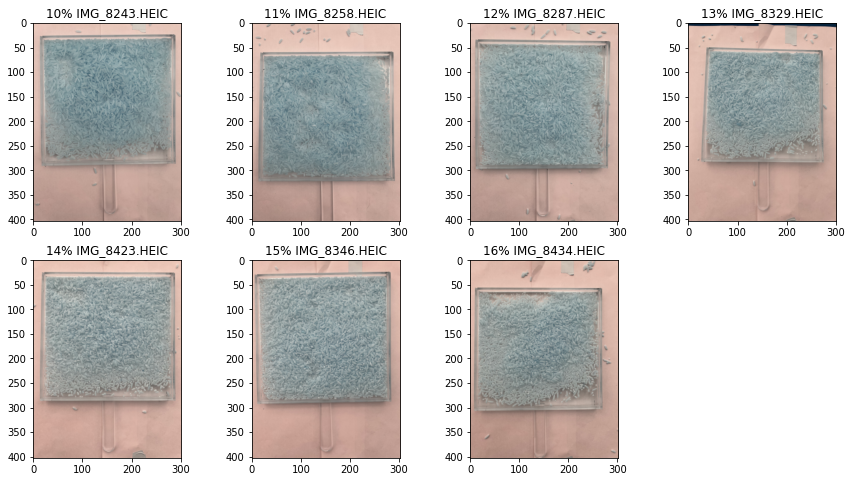

In [189]:
fig=plt.figure(figsize=(15, 8)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_image(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_image(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_image(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_image(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_image(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_image(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_image(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [202]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=3
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        
        graycom = feature.graycomatrix(gray, [1], [0, np.pi/4, np.pi/2, 3*np.pi/4], levels=256)
        # Find the GLCM properties
        contrast = feature.graycoprops(graycom, 'contrast')
        dissimilarity = feature.graycoprops(graycom, 'dissimilarity')
        homogeneity = feature.graycoprops(graycom, 'homogeneity')
        energy = feature.graycoprops(graycom, 'energy')
        correlation = feature.graycoprops(graycom, 'correlation')
        ASM = feature.graycoprops(graycom, 'ASM')
        #contrast+dissimilarity+homogeneity+energy+correlation+ASM
        features = list(contrast[0])+list(dissimilarity[0])+list(homogeneity[0])+list(energy[0])+list(correlation[0])+list(ASM[0])
        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [203]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,scale,height,width,channels,IMAGENAME,HUMIDITY
0,47.398783,94.230101,69.521008,93.106033,4.410955,5.945331,4.597199,5.867623,0.323948,0.264966,...,0.001912,0.001572,0.002078,0.001571,3,120,90,3,IMG_8189.HEIC,10
1,50.800843,103.437258,74.788049,101.771882,4.624625,6.504579,4.958730,6.339722,0.303263,0.229115,...,0.001312,0.000959,0.001325,0.000995,3,120,90,3,IMG_8190.HEIC,10
2,55.481461,120.710131,91.794398,117.023699,4.833333,6.743556,5.328291,6.639411,0.303432,0.230220,...,0.001270,0.000992,0.001288,0.000992,3,120,90,3,IMG_8193.HEIC,10
3,70.887547,114.327353,74.615313,112.328203,5.367697,7.120480,5.422969,7.046171,0.284054,0.217292,...,0.001111,0.000857,0.001116,0.000855,3,120,90,3,IMG_8194.HEIC,10
4,46.622753,93.630441,68.897852,93.900765,4.400655,5.978283,4.582820,5.962704,0.321088,0.249636,...,0.001827,0.001465,0.001907,0.001464,3,120,90,3,IMG_8199.HEIC,10
5,66.267790,113.386460,77.608777,109.768199,5.340824,7.024644,5.390476,6.944670,0.282124,0.215340,...,0.001096,0.000843,0.001101,0.000855,3,120,90,3,IMG_8206.HEIC,10
6,66.539794,119.824568,86.750700,120.908507,5.309457,7.137758,5.672829,7.172505,0.284447,0.213154,...,0.001119,0.000872,0.001111,0.000860,3,120,90,3,IMG_8210.HEIC,10
7,73.243633,159.133226,124.069094,155.671041,5.733333,7.781890,6.250233,7.873855,0.267824,0.201640,...,0.001286,0.000978,0.001353,0.000952,3,120,90,3,IMG_8211.HEIC,10
8,94.103558,148.908696,106.497759,151.401662,6.543633,8.441696,6.601401,8.509772,0.253742,0.186972,...,0.001065,0.000827,0.001126,0.000820,3,120,90,3,IMG_8215.HEIC,10
9,90.492790,149.324993,108.559477,153.473515,6.347472,8.126617,6.307937,8.253989,0.263853,0.197972,...,0.001126,0.000875,0.001263,0.000862,3,120,90,3,IMG_8216.HEIC,10


# Classification

In [155]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-6]
#X

In [156]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [157]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [158]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [159]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [160]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.631579,0.583333,0.642857,0.611650,GLCM,C7,RF_C,25,1008,756,3
1,2,0.736842,0.800000,0.738095,0.767802,GLCM,C7,RF_C,25,1008,756,3
2,3,0.666667,0.747619,0.666667,0.704826,GLCM,C7,RF_C,25,1008,756,3
3,4,0.555556,0.776190,0.595238,0.673776,GLCM,C7,RF_C,25,1008,756,3
4,5,0.555556,0.688095,0.547619,0.609872,GLCM,C7,RF_C,25,1008,756,3
5,6,0.500000,0.547619,0.523810,0.535450,GLCM,C7,RF_C,25,1008,756,3
6,7,0.722222,0.842857,0.690476,0.759095,GLCM,C7,RF_C,25,1008,756,3
7,8,0.777778,0.797619,0.785714,0.791622,GLCM,C7,RF_C,25,1008,756,3
8,9,0.722222,0.785714,0.690476,0.735023,GLCM,C7,RF_C,25,1008,756,3
9,10,0.555556,0.628571,0.547619,0.585309,GLCM,C7,RF_C,25,1008,756,3


In [161]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,GLCM,C7,RF_C,0.642398,0.642857,0.677443,0.719762


### MLP Classifier

In [162]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [163]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [164]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.789474,0.797619,0.761905,0.779353,GLCM,C7,MLP_C,25,1008,756,3
1,2,0.473684,0.535714,0.500000,0.517241,GLCM,C7,MLP_C,25,1008,756,3
2,3,0.777778,0.845238,0.809524,0.826996,GLCM,C7,MLP_C,25,1008,756,3
3,4,0.555556,0.619048,0.571429,0.594286,GLCM,C7,MLP_C,25,1008,756,3
4,5,0.666667,0.690476,0.642857,0.665816,GLCM,C7,MLP_C,25,1008,756,3
5,6,0.611111,0.654762,0.619048,0.636404,GLCM,C7,MLP_C,25,1008,756,3
6,7,0.888889,0.928571,0.857143,0.891429,GLCM,C7,MLP_C,25,1008,756,3
7,8,0.722222,0.797619,0.714286,0.753656,GLCM,C7,MLP_C,25,1008,756,3
8,9,0.666667,0.642857,0.666667,0.654545,GLCM,C7,MLP_C,25,1008,756,3
9,10,0.611111,0.595238,0.571429,0.583090,GLCM,C7,MLP_C,25,1008,756,3


In [165]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,GLCM,C7,MLP_C,0.676316,0.671429,0.690282,0.710714


### XGBoost Classifier

In [166]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [167]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.526316,0.547619,0.523810,0.535450,GLCM,C7,XGB_C,25,1008,756,3
1,2,0.526316,0.595238,0.547619,0.570437,GLCM,C7,XGB_C,25,1008,756,3
2,3,0.611111,0.628571,0.595238,0.611451,GLCM,C7,XGB_C,25,1008,756,3
3,4,0.611111,0.559524,0.571429,0.565414,GLCM,C7,XGB_C,25,1008,756,3
4,5,0.666667,0.735714,0.666667,0.699491,GLCM,C7,XGB_C,25,1008,756,3
5,6,0.666667,0.714286,0.666667,0.689655,GLCM,C7,XGB_C,25,1008,756,3
6,7,0.611111,0.771429,0.571429,0.656535,GLCM,C7,XGB_C,25,1008,756,3
7,8,0.666667,0.892857,0.690476,0.778733,GLCM,C7,XGB_C,25,1008,756,3
8,9,0.666667,0.666667,0.666667,0.666667,GLCM,C7,XGB_C,25,1008,756,3
9,10,0.666667,0.738095,0.642857,0.687192,GLCM,C7,XGB_C,25,1008,756,3


In [168]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,GLCM,C7,XGB_C,0.62193,0.614286,0.646102,0.685


# External validation

In [169]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C7_10,5,"[DATA/TEST/C7/C7_10/IMG_8188.HEIC, DATA/TEST/C..."
1,C7_11,5,"[DATA/TEST/C7/C7_11/IMG_8249.HEIC, DATA/TEST/C..."
2,C7_12,5,"[DATA/TEST/C7/C7_12/IMG_8279.HEIC, DATA/TEST/C..."
3,C7_13,5,"[DATA/TEST/C7/C7_13/IMG_8316.HEIC, DATA/TEST/C..."
4,C7_14,5,"[DATA/TEST/C7/C7_14/IMG_8411.HEIC, DATA/TEST/C..."
5,C7_15,5,"[DATA/TEST/C7/C7_15/IMG_8344.HEIC, DATA/TEST/C..."
6,C7_16,5,"[DATA/TEST/C7/C7_16/IMG_8377.HEIC, DATA/TEST/C..."


In [170]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [171]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        
        graycom = feature.graycomatrix(gray, [1], [0, np.pi/4, np.pi/2, 3*np.pi/4], levels=256)
        # Find the GLCM properties
        contrast = feature.graycoprops(graycom, 'contrast')
        dissimilarity = feature.graycoprops(graycom, 'dissimilarity')
        homogeneity = feature.graycoprops(graycom, 'homogeneity')
        energy = feature.graycoprops(graycom, 'energy')
        correlation = feature.graycoprops(graycom, 'correlation')
        ASM = feature.graycoprops(graycom, 'ASM')
        #contrast+dissimilarity+homogeneity+energy+correlation+ASM
        features = list(contrast[0])+list(dissimilarity[0])+list(homogeneity[0])+list(energy[0])+list(correlation[0])+list(ASM[0])

        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [172]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,scale,height,width,channels,IMAGENAME,HUMIDITY
0,27.353552,47.388004,28.158222,42.633927,2.665811,3.564086,2.674796,3.363914,0.440649,0.386916,...,0.002306,0.001954,0.002291,0.001989,25,1008,756,3,IMG_8188.HEIC,10
1,31.196212,47.797129,28.213967,49.258312,2.917041,3.615228,2.724567,3.705889,0.417916,0.375996,...,0.001858,0.001607,0.001884,0.001582,25,1008,756,3,IMG_8198.HEIC,10
2,33.199463,53.543909,34.924117,56.632425,3.026347,3.850381,3.023585,3.981806,0.401195,0.357087,...,0.001690,0.001427,0.001687,0.001394,25,1008,756,3,IMG_8202.HEIC,10
3,41.785089,63.995736,37.693218,64.172263,3.276072,4.167963,3.118277,4.192868,0.404533,0.356621,...,0.001645,0.001384,0.001677,0.001377,25,1008,756,3,IMG_8203.HEIC,10
4,34.364981,65.153024,43.038674,62.990055,2.980291,3.996605,3.071825,3.928656,0.415001,0.363290,...,0.001937,0.001642,0.001917,0.001647,25,1008,756,3,IMG_8207.HEIC,10
0,29.219400,64.772295,47.067787,64.943486,2.750625,3.721583,2.951493,3.745924,0.423993,0.378659,...,0.002030,0.001711,0.002001,0.001688,25,1008,756,3,IMG_8249.HEIC,11
1,34.733017,54.236944,33.706499,55.956857,3.007536,3.815394,2.932972,3.869600,0.411444,0.367308,...,0.001859,0.001595,0.001854,0.001566,25,1008,756,3,IMG_8251.HEIC,11
2,37.256670,60.211145,37.927794,61.449727,3.089370,4.004269,3.092706,4.035773,0.406703,0.359329,...,0.001885,0.001585,0.001861,0.001563,25,1008,756,3,IMG_8252.HEIC,11
3,33.777229,54.706636,34.087648,57.254857,2.987438,3.895877,2.980620,3.969202,0.411515,0.357246,...,0.001592,0.001310,0.001583,0.001290,25,1008,756,3,IMG_8264.HEIC,11
4,35.106683,56.745619,35.574915,58.143245,3.081344,3.978262,3.078656,4.028425,0.399166,0.349905,...,0.001527,0.001274,0.001503,0.001250,25,1008,756,3,IMG_8272.HEIC,11


In [173]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [174]:
X_test = dtFeaturesTest.values[:, :-6]
#X_test

In [175]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [176]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [177]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.83      1.00      0.91         5
     Class 1       1.00      0.80      0.89         5
     Class 2       0.71      1.00      0.83         5
     Class 3       0.67      0.40      0.50         5
     Class 4       0.60      0.60      0.60         5
     Class 5       0.75      0.60      0.67         5
     Class 6       0.83      1.00      0.91         5

    accuracy                           0.77        35
   macro avg       0.77      0.77      0.76        35
weighted avg       0.77      0.77      0.76        35



## MLP

In [178]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [179]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.80      0.80      0.80         5
     Class 1       0.80      0.80      0.80         5
     Class 2       0.83      1.00      0.91         5
     Class 3       1.00      0.60      0.75         5
     Class 4       0.60      0.60      0.60         5
     Class 5       0.50      0.40      0.44         5
     Class 6       0.71      1.00      0.83         5

    accuracy                           0.74        35
   macro avg       0.75      0.74      0.73        35
weighted avg       0.75      0.74      0.73        35



## XGBC

In [180]:
y_pred = modelXGBC.predict(X_test_scale) 

In [181]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.83      1.00      0.91         5
     Class 1       0.80      0.80      0.80         5
     Class 2       0.80      0.80      0.80         5
     Class 3       1.00      0.80      0.89         5
     Class 4       1.00      0.60      0.75         5
     Class 5       1.00      1.00      1.00         5
     Class 6       0.71      1.00      0.83         5

    accuracy                           0.86        35
   macro avg       0.88      0.86      0.85        35
weighted avg       0.88      0.86      0.85        35

